<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Evaluación final en el test</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

Este es el **único notebook que carga el test**. Reentrena con todo `train` + `development` los sistemas fijados en `modelos_lineales.ipynb` y `modelo_arboles.ipynb`, los evalúa **una sola vez** en `data/processed/test.parquet` y analiza los errores. Nada de lo que se ve aquí se usa para cambiar los modelos; cualquier cambio posterior se reportaría como un sistema aparte. Escribe `resultados/test_final.csv`, `resultados/predicciones_test.csv`, `modelos/modelo_principal.joblib` y figuras en `figuras/`.

## Contenido

    * [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Evaluación](#fase-evaluacion)**
    * [Sección 1: Sistemas fijados antes del test](#seccion-1)
    * [Sección 2: Reentrenamiento y predicción](#seccion-2)
    * [Sección 3: Resultados en el test](#seccion-3)
    * [Sección 4: Brecha entre CV y test](#seccion-4)
    * [Sección 5: Matriz de confusión](#seccion-5)
    * [Sección 6: Análisis de errores](#seccion-6)
    * [Sección 7: Pruebas estadísticas](#seccion-7)
    * [Sección 8: Interpretabilidad: coeficientes](#seccion-8)
    * [Sección 9: Interpretabilidad: LIME](#seccion-9)
    * [Sección 10: Evaluación frente a los objetivos](#seccion-10)
* **[Conclusiones](#conclusiones)**
    * [Sección 11: Resumen por sección](#seccion-11)
    * [Sección 12: Limitaciones y siguientes pasos](#seccion-12)
    * [Sección 13: Referencias](#seccion-13)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas y constantes.
>
> **Qué se espera ver:** el entorno `fakedes`.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import json
import os
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Modelado, evaluación e interpretación
import joblib
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix
from lime.lime_text import LimeTextExplainer

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes

In [2]:
SEMILLA = uf.SEMILLA
COLORES_CLASE = uf.COLORES_CLASE
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
N_BOOTSTRAP = 1000          # remuestreos del test para los intervalos de confianza
N_LIME = 20                 # noticias del test explicadas con LIME (10 por clase)
MUESTRAS_LIME = 500         # perturbaciones por explicación
OFICIALES = {'1.er lugar (GDUFS_DM)': 0.7666, 'Baseline BETO': 0.7321, 'Baseline BoW + SVM': 0.7217, 'Baseline 3-gramas + SVM': 0.7063}
uf.configurar_graficas()
uf.crear_carpetas(uf.RUTA_RESULTADOS, uf.RUTA_FIGURAS, 'modelos')

<a id="fase-evaluacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Evaluación</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Sistemas fijados antes del test</span></div>

> **Qué se hace:** leemos de disco las configuraciones elegidas en el modelado y las listamos con su puntaje de CV.
>
> **Qué se espera ver:** un sistema principal y varios secundarios, todos decididos antes de abrir el test.

**Tabla 1.1.** Sistemas que se evalúan en el test. Solo el principal cuenta para el criterio de éxito; los demás se reportan como referencia.

In [3]:
corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'))
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_lineal.json'), encoding = 'utf-8') as f:
    sel_lin = json.load(f)
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_arboles.json'), encoding = 'utf-8') as f:
    sel_arb = json.load(f)
cv_lin = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'cv_lineales.csv'))
cv_base = cv_lin[cv_lin['etapa'] == 'baselines'].groupby('modelo')['F1_fake'].mean()

sistemas = {
    'LR texto (principal)': ('texto', sel_lin['elegida'], sel_lin['cv_elegida']['F1_fake_mean']),
    'SVM texto (mejor media en CV)': ('texto', sel_lin['mejor_media'], sel_lin['cv_mejor_media']['F1_fake_mean']),
    'SVM texto + χ² (regla original)': ('texto', sel_lin['regla_original'], sel_lin['cv_regla_original']['F1_fake_mean']),
    'Réplica BoW + SVM': ('replica', 'BoW + SVM', cv_base['Réplica BoW + SVM']),
    'Réplica 3-gramas + SVM': ('replica', '3-gramas de caracteres + SVM', cv_base['Réplica 3-gramas de caracteres + SVM']),
    'Random Forest (estilo)': ('estilo', sel_arb['elegida'], sel_arb['cv_elegida']['F1_fake_mean']),
    'Clase mayoritaria': ('mayoritaria', None, cv_base['Clase mayoritaria'])}
pd.DataFrame({'tipo': [t for t, _, _ in sistemas.values()], 'F1 fake en CV': [round(cv, 3) for _, _, cv in sistemas.values()],
              'configuración': [json.dumps(c, ensure_ascii = False) if isinstance(c, dict) else c for _, c, _ in sistemas.values()]},
             index = list(sistemas))

,tipo,F1 fake en CV,configuración
LR texto (principal),texto,0.730,"{""representacion"": ""palabras (1,2) + caractere..."
SVM texto (mejor media en CV),texto,0.733,"{""representacion"": ""palabras (1,2) + caractere..."
SVM texto + χ² (regla original),texto,0.702,"{""representacion"": ""palabras (1,2) + caractere..."
Réplica BoW + SVM,replica,0.707,BoW + SVM
Réplica 3-gramas + SVM,replica,0.679,3-gramas de caracteres + SVM
Random Forest (estilo),estilo,0.608,"{""modelo"": ""RF"", ""parametros"": {""max_depth"": 3..."
Clase mayoritaria,mayoritaria,0.377,NaN


**Tabla 1.2.** Tamaños de entrenamiento y test.

In [4]:
pd.DataFrame({'noticias': [len(corpus), len(test)], '% Fake': [round(100 * corpus['y'].mean(), 1), round(100 * test['y'].mean(), 1)]},
             index = ['entrenamiento (train + development)', 'test'])

,noticias,% Fake
entrenamiento (train + development),961,49.3
test,572,50.0


<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Reentrenamiento y predicción</span></div>

> **Qué se hace:** entrenamos cada sistema con las 961 noticias y predecimos el test una vez.
>
> **Qué se espera ver:** predicciones de los 7 sistemas para las 572 noticias del test.

In [5]:
def construir(tipo, config):
    '''
    Función que construye un sistema sin entrenar a partir de su tipo y configuración

    inputs:
    --------
        tipo (str): 'texto', 'replica', 'estilo' o 'mayoritaria'
        config (dict o str): Configuración guardada en el modelado

    outputs:
    --------
        sklearn estimator: Sistema sin entrenar
    '''
    if tipo == 'texto':
        return uf.construir_pipeline(config)
    if tipo == 'replica':
        return uf.construir_replica(config)
    if tipo == 'estilo':
        return uf.construir_modelo_estilo(config)
    return DummyClassifier(strategy = 'most_frequent')

entrenados, predicciones = {}, {}
for nombre, (tipo, config, _) in sistemas.items():
    entrenados[nombre] = construir(tipo, config).fit(corpus, corpus['Category'])
    predicciones[nombre] = entrenados[nombre].predict(test)
pred_df = pd.DataFrame({'id_unico': test['id_unico'], 'Category': test['Category'], **predicciones})
guardar_csv(pred_df, 'predicciones_test')
joblib.dump(entrenados['LR texto (principal)'], os.path.join('modelos', 'modelo_principal.joblib'))
with open(os.path.join('modelos', 'config_principal.json'), 'w', encoding = 'utf-8') as f:
    json.dump(sel_lin['elegida'], f, ensure_ascii = False, indent = 1)
pd.DataFrame({'sistema': list(predicciones), 'predichas Fake': [int((p == 'Fake').sum()) for p in predicciones.values()]})

,sistema,predichas Fake
0,LR texto (principal),193
1,SVM texto (mejor media en CV),191
2,SVM texto + χ² (regla original),195
3,Réplica BoW + SVM,214
4,Réplica 3-gramas + SVM,222
5,Random Forest (estilo),177
6,Clase mayoritaria,0


<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Resultados en el test</span></div>

> **Qué se hace:** calculamos la métrica oficial y las complementarias, con intervalo de confianza del 95 % por bootstrap, y las comparamos con la tabla oficial.
>
> **Qué se espera ver:** que el principal quede cerca de los baselines oficiales; los intervalos serán de varios puntos porque el test tiene 572 noticias.

#### Glosario de la sección
* **Bootstrap:** remuestrear el test con reemplazo muchas veces y recalcular la métrica; los percentiles 2.5 y 97.5 forman el intervalo de confianza del 95 %.

Usamos los mismos 1,000 remuestreos (semilla fija) para todos los sistemas, así que las diferencias entre sistemas también se pueden medir por bootstrap pareado (Sección 7). **Tabla 3.1.** Métricas en el test.

In [6]:
rng = np.random.default_rng(SEMILLA)
indices_boot = rng.integers(0, len(test), size = (N_BOOTSTRAP, len(test)))
y_test = test['Category'].values

def f1_bootstrap(pred):
    '''
    Función que calcula la F1 de fake en cada remuestreo bootstrap del test

    inputs:
    --------
        pred (numpy.ndarray): Predicciones del sistema sobre el test

    outputs:
    --------
        numpy.ndarray: F1 de fake en cada uno de los N_BOOTSTRAP remuestreos
    '''
    return np.array([uf.f1_fake(y_test[i], pred[i]) for i in indices_boot])

boot = {n: f1_bootstrap(p) for n, p in predicciones.items()}
filas = []
for nombre, pred in predicciones.items():
    m = uf.metricas(y_test, pred)
    filas.append({'sistema': nombre, **{k: round(v, 4) for k, v in m.items()},
                  'IC95 F1_fake': f'[{np.percentile(boot[nombre], 2.5):.3f}, {np.percentile(boot[nombre], 97.5):.3f}]',
                  'F1_fake en CV': round(sistemas[nombre][2], 3)})
resultados_test = pd.DataFrame(filas).set_index('sistema')
guardar_csv(resultados_test, 'test_final', index = True)
resultados_test

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,F1_fake en CV
sistema,,,,,,,,
LR texto (principal),0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",0.730
SVM texto (mejor media en CV),0.6751,0.7676,0.7213,0.7290,0.8429,0.5629,"[0.625, 0.721]",0.733
SVM texto + χ² (regla original),0.6112,0.7179,0.6646,0.6731,0.7538,0.5140,"[0.554, 0.660]",0.702
Réplica BoW + SVM,0.6600,0.7360,0.6980,0.7028,0.7710,0.5769,"[0.608, 0.707]",0.707
Réplica 3-gramas + SVM,0.6181,0.6950,0.6565,0.6608,0.7072,0.5490,"[0.563, 0.665]",0.679
Random Forest (estilo),0.5054,0.6637,0.5846,0.5997,0.6610,0.4091,"[0.446, 0.560]",0.608
Clase mayoritaria,0.0000,0.6667,0.3333,0.5000,0.0000,0.0000,"[0.000, 0.000]",0.377


**Qué se observa.**

* **Principal.** El sistema principal (LR sobre texto) obtiene una F1 de fake de **0.676** (IC95 [0.629, 0.722]), con macro-F1 de 0.722 y exactitud de 0.729. Es el mejor de nuestros sistemas, empatado con la SVM de mejor media (0.675).
* **Frente a la tabla oficial.** Queda por debajo del baseline BoW + SVM (.7217), de BETO (.7321) y del ganador (.7666), y por encima del baseline de 3-gramas (.7063 oficial).
* **Precisión y exhaustividad.** La precisión de *fake* es alta (0.839), pero la exhaustividad es baja (0.566): el modelo predice *fake* en 193 noticias de 572, cuando hay 286. **El principal es conservador: cuando dice "falsa" casi siempre acierta, pero deja pasar el 43 % de las falsas.**
* **Nuestra réplica BoW** obtiene 0.660, contra .7217 de la oficial. La diferencia de .06 indica que el preprocesamiento oficial (lematización, quitar números y puntuación) o algún detalle no descrito importa. Por eso comparamos el principal también con nuestra réplica, que usa los mismos datos preparados.
* **Otros sistemas.** La regla original (SVM + χ²) cae a 0.611, el Random Forest de estilo a 0.505 y la clase mayoritaria da 0.

**No se alcanza el criterio de éxito técnico (superar .7217); el valor oficial queda justo en el extremo superior del intervalo del principal.**

Barras horizontales con el intervalo bootstrap; las líneas verticales son los resultados oficiales en el mismo test (misma partición y métrica).

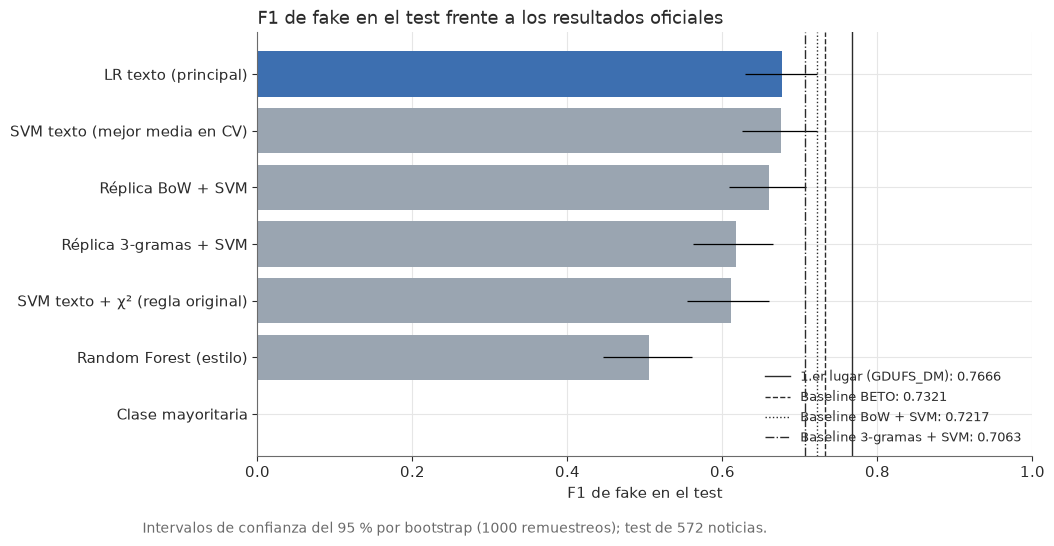

In [7]:
orden = resultados_test['F1_fake'].sort_values().index
fig, ax = plt.subplots(figsize = (10, 5.5))
error = np.array([[resultados_test.loc[n, 'F1_fake'] - np.percentile(boot[n], 2.5) for n in orden],
                  [np.percentile(boot[n], 97.5) - resultados_test.loc[n, 'F1_fake'] for n in orden]])
colores = ['#3D6FB0' if 'principal' in n else '#9aa5b1' for n in orden]
ax.barh(orden, resultados_test.loc[orden, 'F1_fake'], xerr = error, color = colores, error_kw = {'lw': 0.9})
for (etiqueta, valor), estilo in zip(OFICIALES.items(), ['-', '--', ':', '-.']):
    ax.axvline(valor, color = TINTA, linestyle = estilo, linewidth = 1, label = f'{etiqueta}: {valor:.4f}')
ax.set_xlim(0, 1)
ax.set_xlabel('F1 de fake en el test')
ax.set_title('F1 de fake en el test frente a los resultados oficiales')
ax.legend(loc = 'lower right', fontsize = 9)
fig.text(0.01, -0.03, f'Intervalos de confianza del 95 % por bootstrap ({N_BOOTSTRAP} remuestreos); test de 572 noticias.', color = TINTA_SUAVE, fontsize = 10)
guardar(fig, '3_1_f1_test_vs_oficiales')
plt.show()

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Brecha entre CV y test</span></div>

> **Qué se hace:** comparamos la F1 de fake de CV agrupada con la del test para cada sistema (diagnóstico de cambio de dominio).
>
> **Qué se espera ver:** una caída moderada, menor que la que sufriría una validación sin agrupar.

**Tabla 4.1.** F1 de fake en CV agrupada y en el test.

In [8]:
brecha = resultados_test[['F1_fake en CV', 'F1_fake']].rename(columns = {'F1_fake': 'F1_fake en test'})
brecha['test − CV'] = (brecha['F1_fake en test'] - brecha['F1_fake en CV']).round(3)
brecha

,F1_fake en CV,F1_fake en test,test − CV
sistema,,,
LR texto (principal),0.730,0.6764,-0.054
SVM texto (mejor media en CV),0.733,0.6751,-0.058
SVM texto + χ² (regla original),0.702,0.6112,-0.091
Réplica BoW + SVM,0.707,0.6600,-0.047
Réplica 3-gramas + SVM,0.679,0.6181,-0.061
Random Forest (estilo),0.608,0.5054,-0.103
Clase mayoritaria,0.377,0.0000,-0.377


**Qué se observa.** Todos los sistemas caen del CV al test. Los de texto pierden entre 0.047 (réplica BoW) y 0.058 (SVM); el principal pierde 0.054. La regla original (χ²) pierde 0.091 y el bosque de estilo 0.103, en línea con su mayor dependencia del medio (Sección 5 de `modelo_arboles.ipynb`). La caída del principal (0.054) es la mitad de lo que habría sobreestimado una validación con folds aleatorios (+0.107). **La CV agrupada fue optimista en unos 5 puntos, pero mucho menos que la alternativa sin agrupar; el orden entre sistemas se conservó, salvo que la regla original quedó peor que la réplica BoW.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Matriz de confusión</span></div>

> **Qué se hace:** mostramos la matriz de confusión del sistema principal, normalizada por fila.
>
> **Qué se espera ver:** qué clase se confunde más.

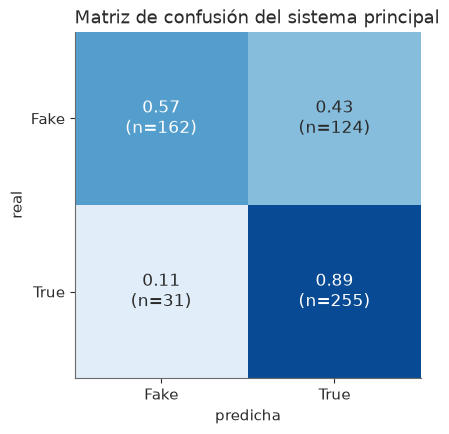

In [9]:
principal = 'LR texto (principal)'
etiquetas = ['Fake', 'True']
cm = confusion_matrix(y_test, predicciones[principal], labels = etiquetas)
cm_norm = cm / cm.sum(axis = 1, keepdims = True)
fig, ax = plt.subplots(figsize = (5.5, 4.5))
ax.imshow(cm_norm, cmap = 'Blues', vmin = 0, vmax = 1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}\n(n={cm[i, j]})', ha = 'center', va = 'center', color = 'white' if cm_norm[i, j] > 0.5 else TINTA, fontsize = 12)
ax.set_xticks([0, 1], etiquetas)
ax.set_yticks([0, 1], etiquetas)
ax.set_xlabel('predicha')
ax.set_ylabel('real')
ax.set_title('Matriz de confusión del sistema principal')
ax.grid(False)
guardar(fig, '5_1_matriz_confusion')
plt.show()

**Qué se observa.** De las 286 falsas, el principal detecta 162 (56.6 %) y confunde 124 con verdaderas. De las 286 verdaderas acierta 255 (89.2 %) y solo 31 las marca como falsas. **El error dominante es dejar pasar noticias falsas; para el objetivo del negocio (priorizar la verificación) conviene más exhaustividad, lo que apunta a ajustar el umbral de decisión con CV (siguiente paso).**

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Análisis de errores</span></div>

> **Qué se hace:** medimos los aciertos del sistema principal por tema, por tipo de fuente, por titular faltante, por longitud y por mención de medios (solo conteos).
>
> **Qué se espera ver:** más errores en las publicaciones de redes sociales, un tipo de texto que no existe en el entrenamiento.

In [10]:
analisis = test.assign(pred = predicciones[principal], acierto = predicciones[principal] == y_test)
analisis['cuartil de longitud'] = pd.qcut(analisis['est_log_palabras'], 4, labels = ['Q1 (más cortas)', 'Q2', 'Q3', 'Q4 (más largas)'])

def por_grupo(columna):
    '''
    Función que resume los aciertos del sistema principal por valores de una columna

    inputs:
    --------
        columna (str): Columna de agrupación

    outputs:
    --------
        pandas.DataFrame: Noticias, falsas, exactitud, falsas detectadas y verdaderas acertadas por grupo
    '''
    g = analisis.groupby(columna, observed = True)
    return pd.DataFrame({'noticias': g.size(), 'falsas': g['y'].sum(),
                         'exactitud': g['acierto'].mean().round(3),
                         'falsas detectadas (%)': (100 * g.apply(lambda d: d.loc[d['y'] == 1, 'acierto'].mean(), include_groups = False)).round(1),
                         'verdaderas acertadas (%)': (100 * g.apply(lambda d: d.loc[d['y'] == 0, 'acierto'].mean(), include_groups = False)).round(1)})

### 6.1 Por tema (Tabla 6.1)

In [11]:
por_grupo('Topic').sort_values('noticias', ascending = False)

,noticias,falsas,exactitud,falsas detectadas (%),verdaderas acertadas (%)
Topic,,,,,
COVID-19,237,119,0.717,53.8,89.8
Society,195,96,0.754,60.4,89.9
Politics,107,54,0.720,55.6,88.7
International,14,7,0.857,71.4,100.0
Science,13,7,0.615,57.1,66.7
Environment,4,2,0.500,50.0,50.0
Sport,2,1,0.500,0.0,100.0


### 6.2 Por tipo de texto y formato (Tabla 6.2)

La bandera `fuente_verificador` aproxima las publicaciones de redes sociales (análisis exploratorio, Sección 13).

In [12]:
pd.concat({c: por_grupo(c) for c in ['fuente_verificador', 'sin_titular_original', 'texto_corto', 'menciona_medio']}, names = ['bandera', 'valor'])

noticias  falsas  exactitud  \
bandera              valor                                
fuente_verificador   False       454     169      0.740   
                     True        118     117      0.686   
sin_titular_original False       500     214      0.716   
                     True         72      72      0.819   
texto_corto          False       568     282      0.727   
                     True          4       4      1.000   
menciona_medio       False       500     254      0.736   
                     True         72      32      0.681   

                            falsas detectadas (%)  verdaderas acertadas (%)  
bandera              valor                                                   
fuente_verificador   False                   48.5                      89.1  
                     True                    68.4                     100.0  
sin_titular_original False                   48.1                      89.2  
                     True                    81.9                       NaN  
texto_corto          False                   56.0                      89.2  
                     True                   100.0                       NaN  
menciona_medio       False                   59.1                      88.6  
                     True                    37.5                      92.5

### 6.3 Por longitud (Tabla 6.3)

In [13]:
por_grupo('cuartil de longitud')

,noticias,falsas,exactitud,falsas detectadas (%),verdaderas acertadas (%)
cuartil de longitud,,,,,
Q1 (más cortas),143,110,0.762,78.2,69.7
Q2,144,81,0.667,54.3,82.5
Q3,142,62,0.676,38.7,90.0
Q4 (más largas),143,33,0.811,24.2,98.2


**Qué se observa.**

* **Por tema** (Tabla 6.1). COVID-19, el tema nuevo, queda en una exactitud de 0.717, comparable con Política (0.720) y Sociedad (0.754), como reportó el overview. En los tres, las falsas detectadas van del 54 % al 60 % y las verdaderas acertadas rondan el 89 %.
* **Publicaciones de redes** (Tabla 6.2). Contra lo esperado, las falsas de fuentes verificadoras o redes sociales se detectan **mejor** (68.4 %, 80 de 117) que las demás falsas (48.5 %, 82 de 169). Las 72 sin titular se detectan en el 81.9 % y las 4 cortas en el 100 %. Las falsas que mencionan un medio conocido se detectan peor (37.5 %).
* **Por longitud** (Tabla 6.3). Es el factor más fuerte: de las falsas más cortas (Q1) se detecta el 78.2 % y de las más largas (Q4) solo el 24.2%. En las verdaderas pasa lo contrario: 69.7 % en Q1 contra 98.2 % en Q4.
* **El par casi idéntico del test** (Tabla 6.4). Ambas noticias se predicen como verdaderas: acierta la 109 y falla la 353.

**Hallazgo: el modelo aprendió que "corto e informal = falso" y "largo = verdadero". En el test, las falsas que parecen notas de prensa (largas, citando datos y medios) pasan como verdaderas, y las publicaciones de redes, cortas e informales, se detectan bien.**

### 6.4 El par casi idéntico del test (Tabla 6.4)

El análisis exploratorio encontró un par de noticias casi idénticas con clases distintas (Ids 109 y 353 del test).

In [14]:
analisis.loc[analisis['Id'].isin([109, 353]), ['Id', 'Category', 'pred', 'acierto']]

,Id,Category,pred,acierto
108,109,True,True,True
352,353,Fake,True,False


<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Pruebas estadísticas</span></div>

> **Qué se hace:** comparamos el principal con la réplica BoW (bootstrap pareado y McNemar) y probamos si las publicaciones de redes se detectan peor (Fisher).
>
> **Qué se espera ver:** que la diferencia con la réplica BoW no sea concluyente con 572 noticias.

#### Glosario de la sección
* **McNemar exacta:** prueba binomial sobre las noticias en que solo uno de los dos sistemas acierta.
* **Prueba exacta de Fisher:** prueba de independencia para tablas 2 × 2 que no requiere frecuencias esperadas ≥ 5.

Corregimos por Bonferroni con m = 2 (las dos pruebas de hipótesis). **Tabla 7.1.** Resultados.

In [15]:
dif_boot = boot[principal] - boot['Réplica BoW + SVM']
ok_p, ok_b = predicciones[principal] == y_test, predicciones['Réplica BoW + SVM'] == y_test
b, c = int((ok_p & ~ok_b).sum()), int((~ok_p & ok_b).sum())
p_mcnemar = stats.binomtest(b, b + c, 0.5).pvalue
falsas = analisis[analisis['y'] == 1]
tabla_fisher = pd.crosstab(falsas['fuente_verificador'], falsas['acierto'])
p_fisher = stats.fisher_exact(tabla_fisher.values)[1]
pd.DataFrame([
    ('Principal − réplica BoW: diferencia de F1 de fake (bootstrap pareado)', f'{dif_boot.mean():+.3f}', f'IC95 [{np.percentile(dif_boot, 2.5):+.3f}, {np.percentile(dif_boot, 97.5):+.3f}]', '—'),
    ('McNemar exacta (aciertos principal frente a réplica BoW)', f'solo principal: {b}; solo réplica: {c}', f'p = {p_mcnemar:.3f}', f'{min(1, 2 * p_mcnemar):.3f}'),
    ('Fisher: falsas detectadas, verificador o red frente a otras fuentes', ' / '.join(f'{i}: {tabla_fisher.loc[i, True]} de {tabla_fisher.loc[i].sum()}' for i in tabla_fisher.index), f'p = {p_fisher:.3g}', f'{min(1, 2 * p_fisher):.3g}'),
], columns = ['prueba', 'datos', 'resultado', 'p Bonferroni'])

,prueba,datos,resultado,p Bonferroni
0,Principal − réplica BoW: diferencia de F1 de f...,+0.016,"IC95 [-0.028, +0.060]",—
1,McNemar exacta (aciertos principal frente a ré...,solo principal: 58; solo réplica: 43,p = 0.163,0.327
2,"Fisher: falsas detectadas, verificador o red f...",False: 82 de 169 / True: 80 de 117,p = 0.00103,0.00206


**Qué se observa.**

* **Frente a la réplica BoW.** La ventaja del principal es de +0.016 en F1 de fake, con IC95 bootstrap pareado [−0.028, +0.060], que incluye el 0. McNemar tampoco es significativa: 58 noticias las acierta solo el principal y 43 solo la réplica (p = 0.163; 0.327 corregido). No hay evidencia de que el principal sea mejor que la réplica con el mismo preprocesamiento.
* **Publicaciones de redes.** La mejor detección de las falsas de verificadores o redes sí es significativa (Fisher p = 0.001; 0.002 corregido).

**La diferencia entre nuestros dos mejores enfoques está dentro del ruido de un test de 572 noticias; la diferencia por tipo de texto, no.**

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Interpretabilidad: coeficientes</span></div>

> **Qué se hace:** listamos los atributos con mayor peso hacia cada clase en la regresión logística entrenada con todo el corpus.
>
> **Qué se espera ver:** palabras y fragmentos de palabra asociados al estilo de cada clase.

⚠️ Un coeficiente indica asociación dentro del modelo, no causa. Los atributos son palabras o n-gramas de caracteres sueltos.

En scikit-learn las clases se ordenan como `[Fake, True]`, así que un coeficiente negativo empuja hacia *Fake*. Los n-gramas de caracteres se muestran entre comillas para ver los espacios. **Tabla 8.1.** Los 15 atributos con más peso hacia cada clase.

In [16]:
modelo_p = entrenados[principal]
nombres = modelo_p.named_steps['representacion'].get_feature_names_out()
coef = modelo_p.named_steps['clasificador'].coef_[0]
atributos = pd.DataFrame({'atributo': [n.split('__')[-1] for n in nombres],
                          'tipo': ['caracteres' if '__caracteres__' in n else 'palabras' for n in nombres], 'coeficiente': coef})
atributos['atributo'] = np.where(atributos['tipo'] == 'caracteres', '"' + atributos['atributo'] + '"', atributos['atributo'])
hacia_fake = atributos.nsmallest(15, 'coeficiente').reset_index(drop = True)
hacia_true = atributos.nlargest(15, 'coeficiente').reset_index(drop = True)
pd.concat({'hacia Fake': hacia_fake, 'hacia True': hacia_true}, axis = 1).round(3)

hacia Fake                         hacia True                      
     atributo      tipo coeficiente     atributo      tipo coeficiente
0          ya  palabras      -1.150        en el  palabras       1.303
1        esto  palabras      -0.894       number  palabras       1.118
2        todo  palabras      -0.852    en number  palabras       1.090
3         que  palabras      -0.763        en la  palabras       0.984
4         nos  palabras      -0.757    de number  palabras       0.861
5         así  palabras      -0.715    number de  palabras       0.848
6        pues  palabras      -0.706      aseguró  palabras       0.829
7          de  palabras      -0.692        cinco  palabras       0.810
8          se  palabras      -0.691       través  palabras       0.720
9          lo  palabras      -0.683      destacó  palabras       0.711
10     ya que  palabras      -0.640      domingo  palabras       0.703
11      no se  palabras      -0.628        sobre  palabras       0.679
12       será  palabras      -0.628          hay  palabras       0.675
13    fuentes  palabras      -0.624  acuerdo con  palabras       0.666
14       pero  palabras      -0.604        julio  palabras       0.658

**Qué se observa.** Los 15 atributos con más peso son palabras, no fragmentos de caracteres. Hacia *Fake* empujan conectores y palabras de discurso argumentativo o conversacional: *ya*, *esto*, *todo*, *que*, *nos*, *así*, *pues*, *ya que*, *pero*. Hacia *True* empujan marcas de redacción periodística: la marca de número anonimizado (*number*, *en number*, *de number*), verbos de atribución (*aseguró*, *destacó*), fechas (*domingo*, *julio*, *cinco*) y *de acuerdo con*. **El modelo distingue registros (nota de prensa contra texto de opinión o rumor), no hechos; eso explica el hallazgo de la Sección 6: una falsa escrita como nota de prensa pasa como verdadera.**

<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: Interpretabilidad: LIME</span></div>

> **Qué se hace:** explicamos 20 noticias del test (10 por clase) con LIME y comparamos sus pesos con los coeficientes del modelo.
>
> **Qué se espera ver:** explicaciones locales coherentes con los coeficientes (correlación de Spearman positiva) y un R² local moderado.

⚠️ LIME es local (explica una noticia, no el modelo), tiene azar (fijamos la semilla) y supone palabras independientes; con n-gramas de caracteres, quitar una palabra también quita sus fragmentos.

#### Glosario de la sección
* **LIME:** explica una predicción perturbando el texto (quitando palabras), preguntando al modelo, ponderando las perturbaciones por cercanía y ajustando un modelo lineal local cuyos pesos se leen.
* **R² local:** qué tan bien el modelo lineal local reproduce al modelo real en las perturbaciones.

**Tabla 9.1.** R² local y correlación de Spearman entre el peso de LIME de cada palabra y su coeficiente de unigrama en el modelo (signo invertido para que positivo = hacia *Fake*), por noticia explicada.

In [17]:
muestra = pd.concat([test[test['Category'] == c].sample(N_LIME // 2, random_state = SEMILLA) for c in ['Fake', 'True']])
explicador = LimeTextExplainer(class_names = ['Fake', 'True'], random_state = SEMILLA)
predecir = lambda textos: modelo_p.predict_proba(pd.DataFrame({'titular_sin_medio': [''] * len(textos), 'texto_sin_medio': list(textos)}))
coef_unigrama = {n.split('__')[-1]: -c for n, c in zip(nombres, coef) if '__palabras__' in n and ' ' not in n.split('__')[-1]}

filas_lime, pesos_lime = [], []
for _, noticia in muestra.iterrows():
    exp = explicador.explain_instance(noticia['texto_sin_medio'], predecir, labels = (0,), num_features = 10, num_samples = MUESTRAS_LIME)
    r2 = exp.score[0] if isinstance(exp.score, dict) else exp.score
    pares = [(w, p, coef_unigrama[w.lower()]) for w, p in exp.as_list(label = 0) if w.lower() in coef_unigrama]
    rho = stats.spearmanr([p for _, p, _ in pares], [c for _, _, c in pares])[0] if len(pares) >= 3 else np.nan
    pesos_lime += pares
    filas_lime.append({'Id': noticia['Id'], 'clase': noticia['Category'], 'predicha': modelo_p.predict(noticia.to_frame().T)[0],
                       'R² local': round(r2, 3), 'palabras con coeficiente': len(pares), 'Spearman': round(rho, 3) if pd.notna(rho) else np.nan})
tabla_lime = pd.DataFrame(filas_lime)
tabla_lime

,Id,clase,predicha,R² local,palabras con coeficiente,Spearman
0,25,Fake,Fake,0.645,9,0.583
1,544,Fake,True,0.796,10,0.903
2,299,Fake,True,0.884,10,0.745
3,433,Fake,Fake,0.768,10,0.903
4,466,Fake,True,0.640,7,0.857
5,323,Fake,True,0.761,10,0.770
6,569,Fake,Fake,0.646,10,0.952
7,154,Fake,Fake,0.561,10,0.515
8,402,Fake,Fake,0.536,10,0.782
9,72,Fake,True,0.787,10,0.806


**Tabla 9.2.** Resumen de LIME.

In [18]:
rho_total = stats.spearmanr([p for _, p, _ in pesos_lime], [c for _, _, c in pesos_lime])
pd.Series({'mediana del R² local': tabla_lime['R² local'].median(), 'mediana de Spearman por noticia': tabla_lime['Spearman'].median(),
           'Spearman con todas las palabras juntas': round(rho_total[0], 3), 'p (todas juntas)': rho_total[1],
           'pares palabra–coeficiente': len(pesos_lime)}, name = 'valor').to_frame()

,valor
mediana del R² local,7.550000e-01
mediana de Spearman por noticia,7.945000e-01
Spearman con todas las palabras juntas,8.340000e-01
p (todas juntas),6.337055e-51
pares palabra–coeficiente,1.920000e+02


**Qué se observa.** En las 20 noticias explicadas, la mediana del R² local de LIME es 0.755: el modelo lineal local reproduce razonablemente al modelo. Los pesos de LIME coinciden con los coeficientes de unigrama del modelo: Spearman mediana por noticia de 0.79 y de 0.834 con los 192 pares juntos (p < 0.001). 5 de las 10 falsas de la muestra se predicen como verdaderas, consistente con la exhaustividad de 0.566. **LIME confirma, noticia por noticia, que las decisiones se apoyan en las mismas palabras de registro de la Tabla 8.1; como el modelo es lineal, la explicación local y la global coinciden, que es lo esperado.**

<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: Evaluación frente a los objetivos</span></div>

> **Qué se hace:** respondemos las preguntas de la fase de evaluación de CRISP-DM: si el modelo cumple los objetivos del negocio, qué se aprendió y qué sigue.
>
> **Qué se espera ver:** una respuesta directa al criterio de éxito de la Sección 1.4 del análisis exploratorio.

**¿El modelo cumple los objetivos del negocio?** Parcialmente.

| Objetivo (análisis exploratorio, 1.2 y 1.4) | Resultado | ¿Se cumple? |
|:--|:--|:--|
| Superar el baseline BoW + SVM oficial (.7217) en el test | F1 de fake = 0.676 (IC95 [0.629, 0.722]) | ❌ No; el oficial queda en el borde superior del intervalo |
| Superar a un baseline con el mismo preprocesamiento | +0.016 sobre nuestra réplica BoW (IC95 [−0.028, +0.060]) | ⚠️ No demostrado |
| Usar solo titular y texto, sin atajos de medio | Sin fuente, enlace, tema ni nombres de medio | ✅ Sí |
| Explicar las decisiones | Coeficientes y LIME coherentes (Spearman 0.83) | ✅ Sí |
| Demostración en línea (API) | Modelo serializado en `modelos/`; la API queda planeada | ⏳ Pendiente |

**¿Qué conocimiento se obtuvo?**

1. En este corpus la etiqueta se asocia más con el registro (nota de prensa contra texto informal) y la longitud que con el contenido.
2. Las fuentes y los duplicados dan atajos que inflan la validación entre 0.09 y 0.14 si no se controlan.
3. COVID-19 no fue más difícil que los temas conocidos.

**¿Es útil?** Como filtro de alta precisión (84 % de las que marca son falsas) sí lo es para priorizar. Como detector exhaustivo no: deja pasar 43 % de las falsas, sobre todo las que imitan notas de prensa.

**Revisión del proceso:** el protocolo funcionó como se diseñó. El test se usó una sola vez y la única regla cambiada (selección) se revisó antes de abrirlo. La brecha CV–test de 0.054 fue moderada.

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-11"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 11: Resumen por sección</span></div>

> **Qué se hace:** reunimos los resultados de la evaluación.
>
> **Qué se espera ver:** la tabla final del proyecto.

**Tabla 11.1.** Resultados finales en el test (F1 de fake; misma partición y métrica que la tabla oficial).

| Sistema | CV agrupada | Test | IC95 test |
|:--|--:|--:|:--|
| **LR texto (principal)** | 0.730 | **0.676** | [0.629, 0.722] |
| SVM texto (mejor media en CV) | 0.733 | 0.675 | [0.625, 0.721] |
| Réplica BoW + SVM (nuestra) | 0.707 | 0.660 | [0.608, 0.707] |
| Réplica 3-gramas + SVM (nuestra) | 0.679 | 0.618 | [0.563, 0.665] |
| SVM texto + χ² (regla original) | 0.702 | 0.611 | [0.554, 0.660] |
| Random Forest (estilo) | 0.608 | 0.505 | [0.446, 0.560] |
| *Oficial: baseline BoW + SVM* | — | *0.7217* | — |
| *Oficial: baseline BETO* | — | *0.7321* | — |
| *Oficial: 1.er lugar (GDUFS_DM)* | — | *0.7666* | — |

| Sección | Hallazgo principal | Salidas |
|:--|:--|:--|
| 3. Resultados | 0.676; precisión 0.839, exhaustividad 0.566 | `test_final.csv`, Figura 3.1 |
| 4. Brecha | El principal cae 0.054 del CV al test | Tabla 4.1 |
| 6. Errores | Falsas largas: 24 % detectadas; falsas de redes: 68 % | Tablas 6.1 a 6.3 |
| 7. Pruebas | Principal ≈ réplica BoW (McNemar p corregido = 0.327) | Tabla 7.1 |
| 8–9. Interpretación | Registro periodístico frente a informal; LIME coherente (ρ = 0.83) | Tablas 8.1 y 9.2 |


<a id="seccion-12"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 12: Limitaciones y siguientes pasos</span></div>

> **Qué se hace:** listamos qué quedó sin resolver y qué decisiones podrían cambiar los resultados.
>
> **Qué se espera ver:** pendientes para el equipo.

**Limitaciones:**

* **Criterio de éxito.** No se alcanzó: 0.676 frente a .7217. Nuestra réplica del baseline oficial también queda .06 por debajo, así que parte de la diferencia viene del preprocesamiento (el oficial lematiza y quita números y puntuación), no solo del modelo.
* **Sesgo de longitud y registro.** Las falsas largas o escritas como nota de prensa casi no se detectan.
* **Test pequeño.** 572 noticias: los intervalos miden ±0.05.
* **Pares.** No se pudieron reconstruir la mayoría de los pares verdadera–falsa; el 80 % de los candidatos quedó repartido entre folds.

**Decisiones que podrían cambiar los resultados** (cualquier prueba nueva se elige en CV y se reporta en el test como sistema aparte):

1. Ajustar el umbral de decisión en CV para subir la exhaustividad.
2. Replicar el preprocesamiento oficial (lematización, sin números).
3. Truncado cabeza + cola con BETO (planeado).
4. Ensamble texto + estilo + transformer, dada la complementariedad observada.

Detalle en `notas/siguientes_pasos.md`.

<a id="seccion-13"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 13: Referencias</span></div>

> **Qué se hace:** fuentes citadas.
>
> **Qué se espera ver:** referencias completas.

1. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223–231.
2. Huang, X., Xiong, J. y Jiang, S. (2021). GDUF_DM at FakeDeS 2021: Spanish Fake News Detection with BERT and Sample Memory. *CEUR-WS* Vol. 2943, 621–629.
3. Ribeiro, M. T., Singh, S. y Guestrin, C. (2016). "Why Should I Trust You?": Explaining the Predictions of Any Classifier. En *KDD 2016* (LIME).
4. Dror, R., Baumer, G., Shlomov, S. y Reichart, R. (2018). The Hitchhiker's Guide to Testing Statistical Significance in Natural Language Processing. En *ACL 2018*.
5. Efron, B. y Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
6. Grave, I. (agosto de 2026). Minería de Datos: primera sesión (fase de evaluación de CRISP-DM).